# 01. 탐색적 데이터 분석(EDA) — 서울 출퇴근 혼잡과 이동 격차

이 노트북은 `src/analysis/` 스크립트가 만든 그림·표를 불러와 해석을 붙인다. 그림을 다시 만들려면:
```
.venv/bin/python src/analysis/eda_traffic.py
.venv/bin/python src/analysis/eda_transit.py
.venv/bin/python src/analysis/eda_factors.py
```
**데이터 기간**: 도로 속도 2026-10-14(수) 01시~10-15(목) 09시(33시간) · 교통량 2026-10-14·15 및 2024~2025 첨두 전후 · 대중교통 2024-01~2026-09 월 합계.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG, TAB, PROC = ROOT/'outputs/figures', ROOT/'outputs/tables', ROOT/'data/processed'
def show(name, width=900):
    display(Image(filename=str(FIG/f'{name}.png'), width=width))
def table(name):
    return pd.read_csv(TAB/f'fig_{name}.csv')

## 0. 데이터 규모와 품질

In [2]:
q = {p.stem.replace('quality_', ''): pd.read_csv(p, index_col=0) for p in sorted(TAB.glob('quality_*.csv'))}
pd.DataFrame({k: {'컬럼 수': len(v), '결측 있는 컬럼': int((v.missing > 0).sum()), '최대 결측률(%)': v.missing_pct.max()} for k, v in q.items()}).T

,컬럼 수,결측 있는 컬럼,최대 결측률(%)
bus_monthly_hourly,18.0,4.0,9.13
smart_intersection_hourly,22.0,1.0,79.26
speed_hourly,27.0,8.0,100.00
subway_monthly_hourly,15.0,4.0,37.29
volume_hourly,16.0,1.0,100.00
volume_raw_lane,6.0,0.0,0.00
weather_hourly,15.0,3.0,96.09


## A. 혼잡 현황 — 언제 막히는가

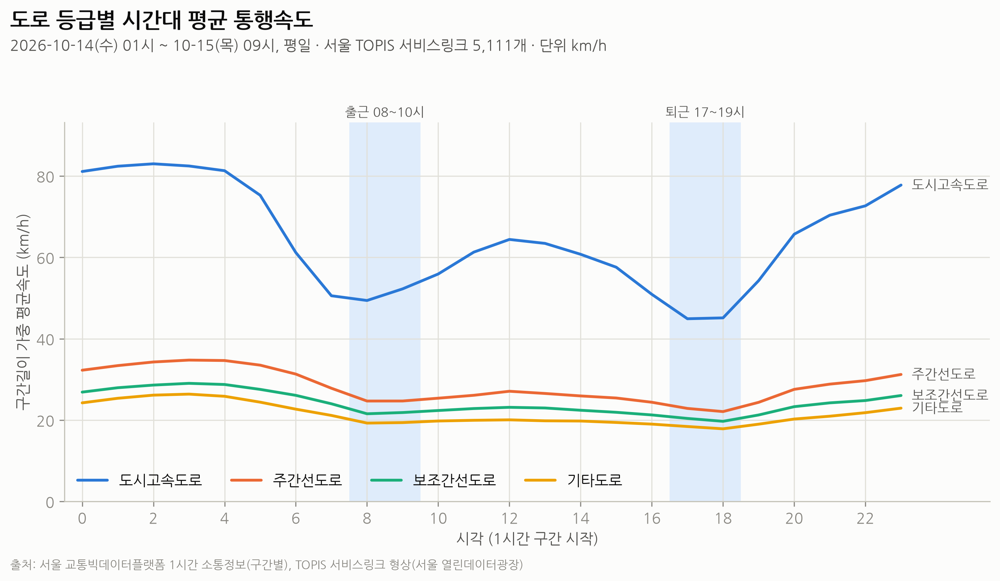

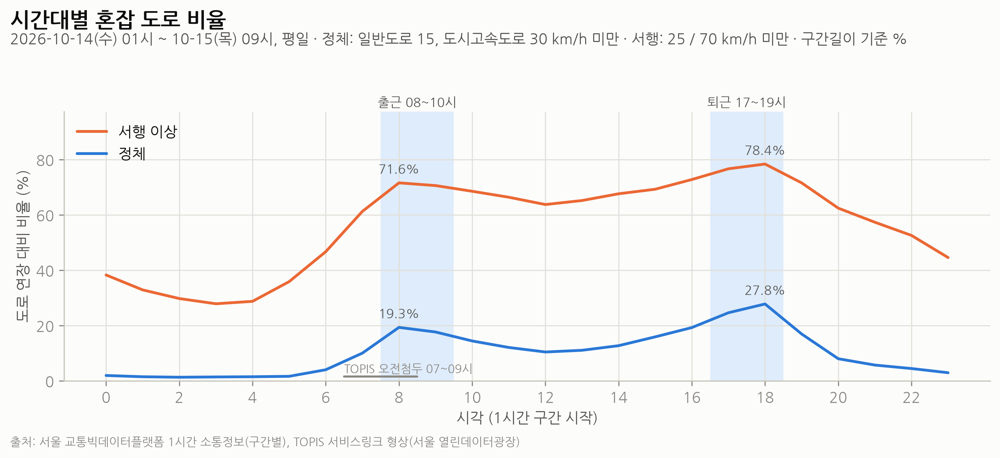

In [3]:
show('A01_시간대별_도로등급별_평균속도'); show('A02_시간대별_혼잡도로비율')

In [4]:
t = table('A02_시간대별_혼잡도로비율')
t.loc[t.정체비율_pct.idxmax()], t[t.시작시각.isin([7, 8, 9])]

(시작시각          18.000000
 정체비율_pct      27.754864
 서행이상비율_pct    78.351498
 Name: 18, dtype: float64,
    시작시각   정체비율_pct  서행이상비율_pct
 7     7   9.986478   61.228668
 8     8  19.298726   71.550284
 9     9  17.625882   70.568244)

- 정체 연장비율 최대: 퇴근 18~19시 27.8%, 출근 08~09시 19.3%.
- 원문 출근 정의(08~10시)와 TOPIS(07~09시) 모두 08~09시를 포함한다. 09~10시는 이미 감소 구간.

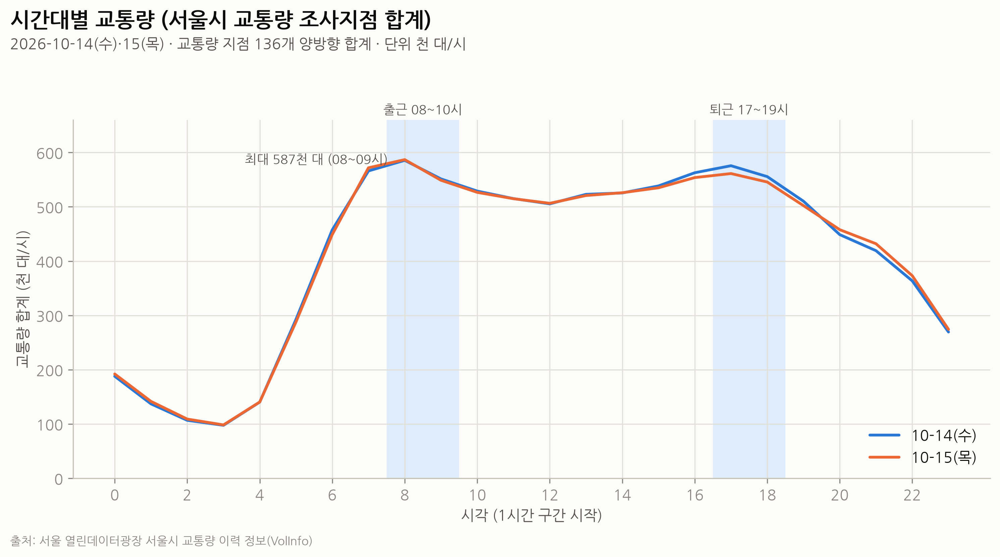

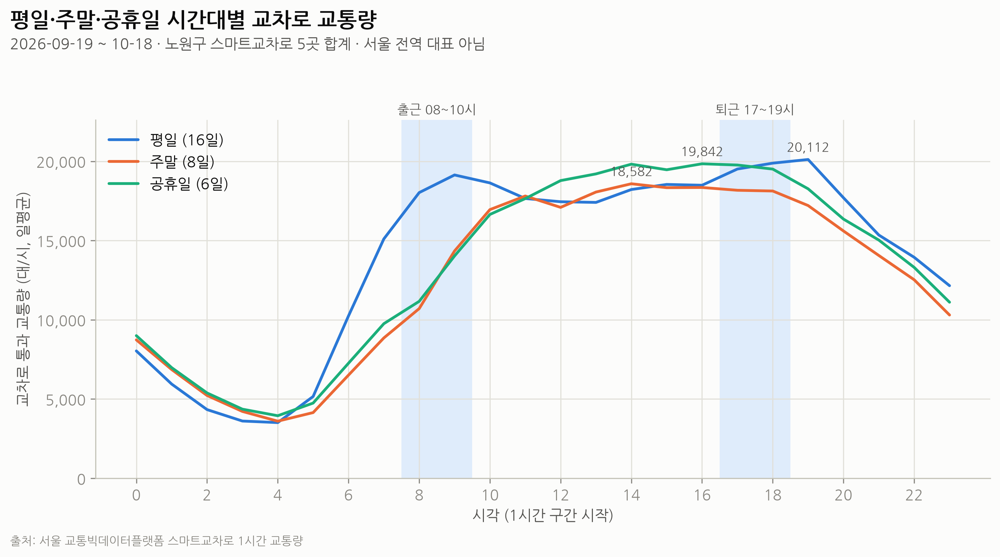

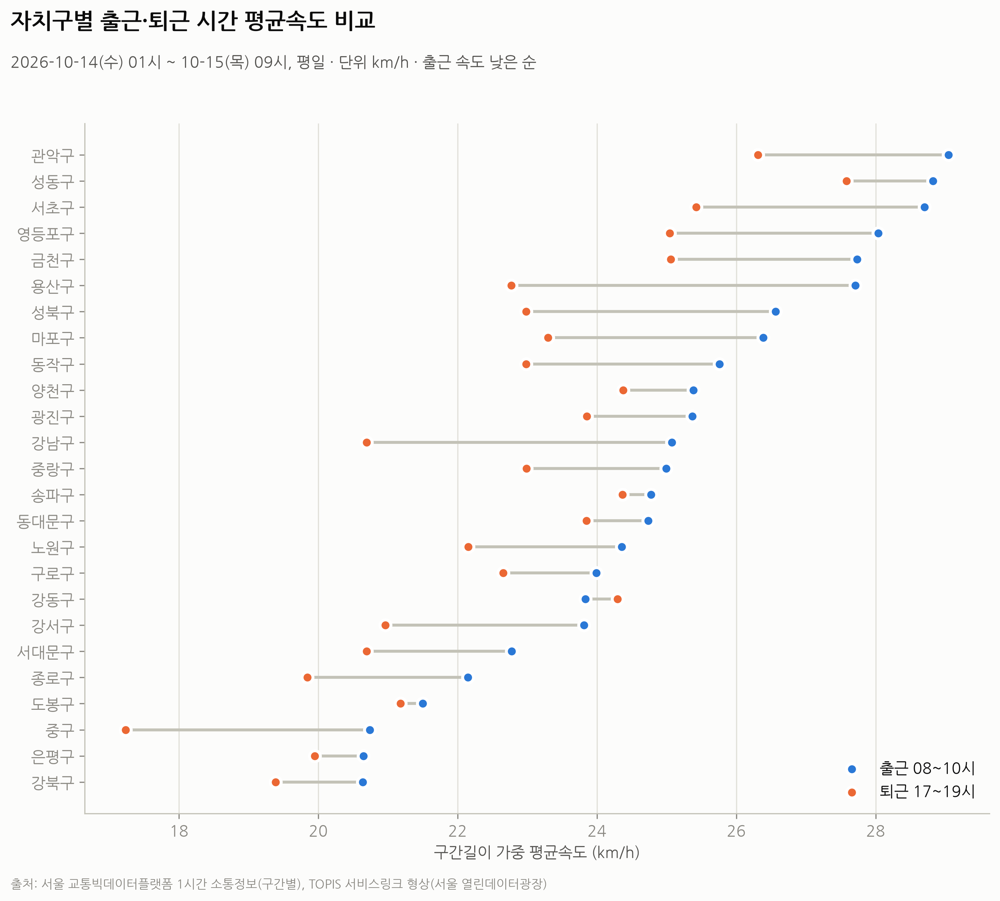

In [5]:
show('A04_시간대별_교통량'); show('A05_요일유형별_교차로교통량'); show('A03_자치구별_출근퇴근_속도비교', 700)

## B. 공간 — 어디가 막히는가

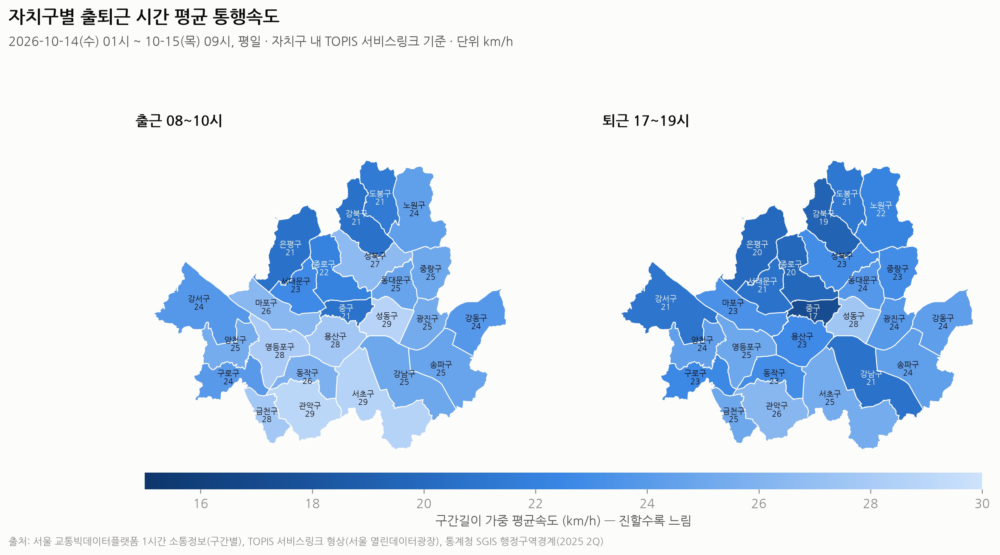

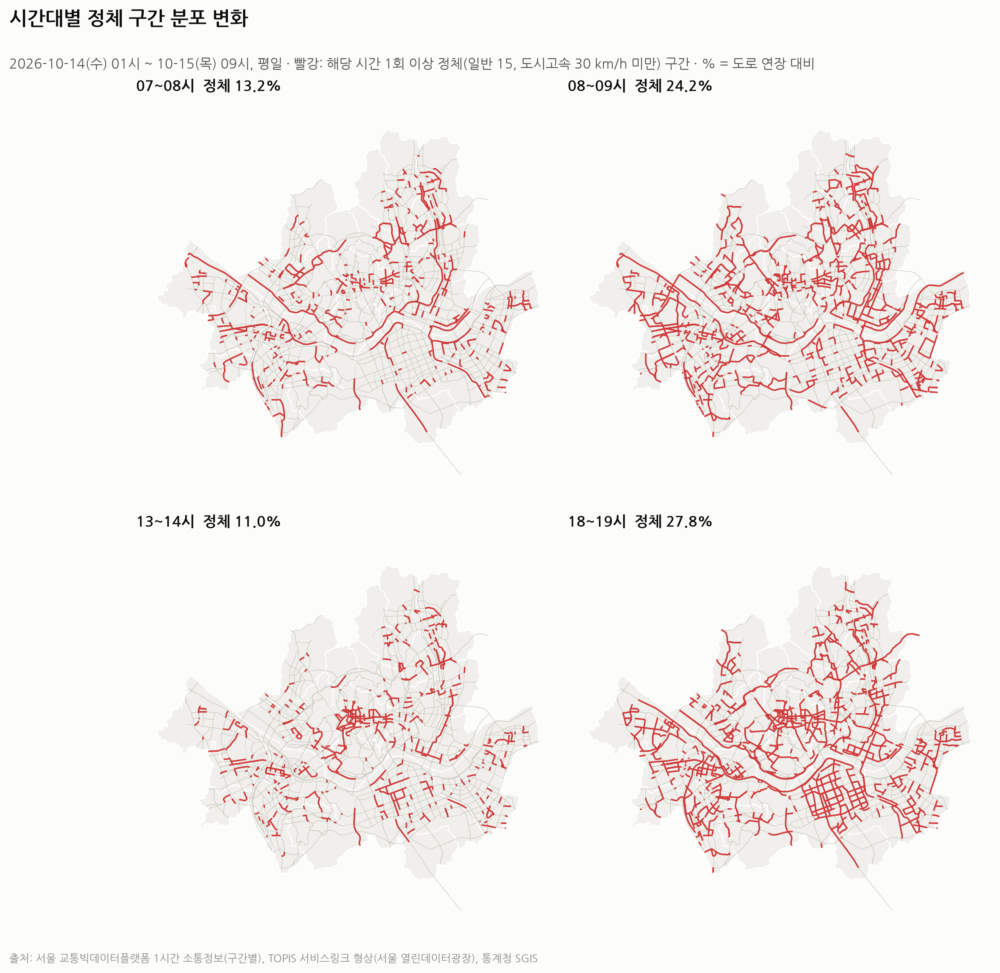

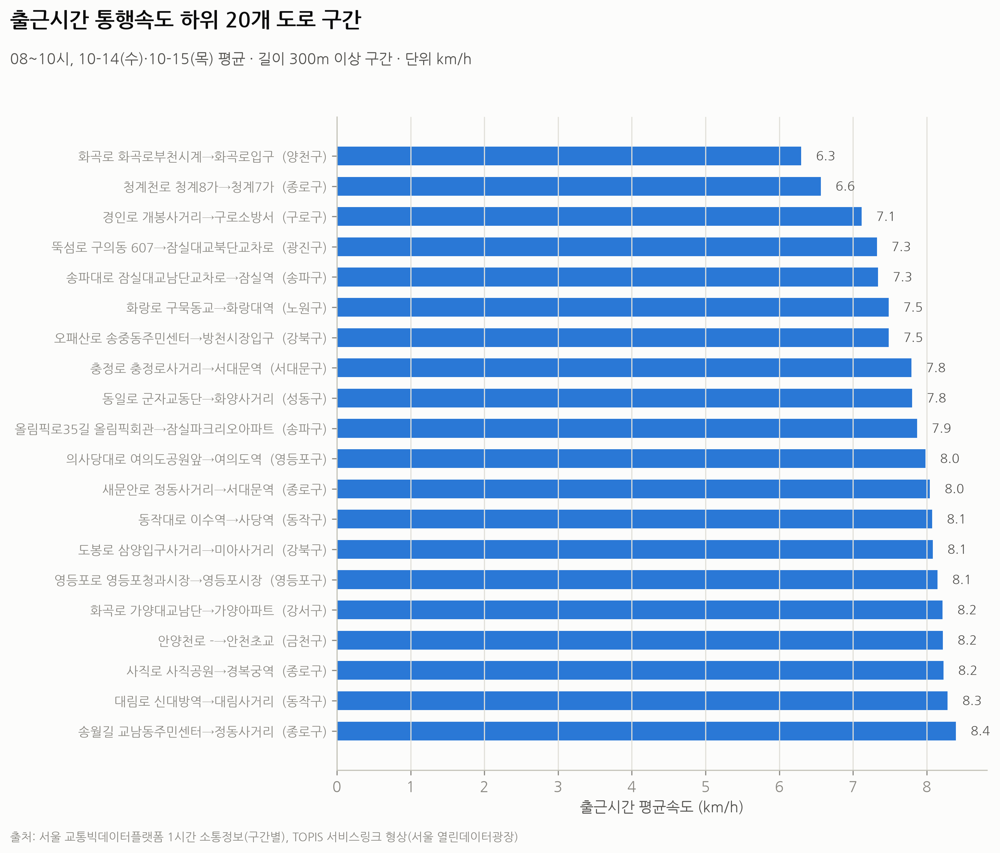

In [6]:
show('B01_자치구별_출퇴근_평균속도_지도'); show('B04_시간대별_정체핫스팟', 800); show('B03_출근시간_혼잡상위20구간', 800)

In [7]:
table('B01_자치구별_출퇴근_평균속도_지도').sort_values('출근_평균속도').head(6)

,자치구,출근_평균속도,퇴근_평균속도
2,강북구,20.6,19.4
21,은평구,20.6,20.0
23,중구,20.7,17.2
9,도봉구,21.5,21.2
22,종로구,22.1,19.8
13,서대문구,22.8,20.7


인터랙티브 지도: `outputs/html/B02_구간별_소통등급_지도_08시.html` (브라우저로 열기).

## C. 대중교통 수요 — 누가 이동하는가

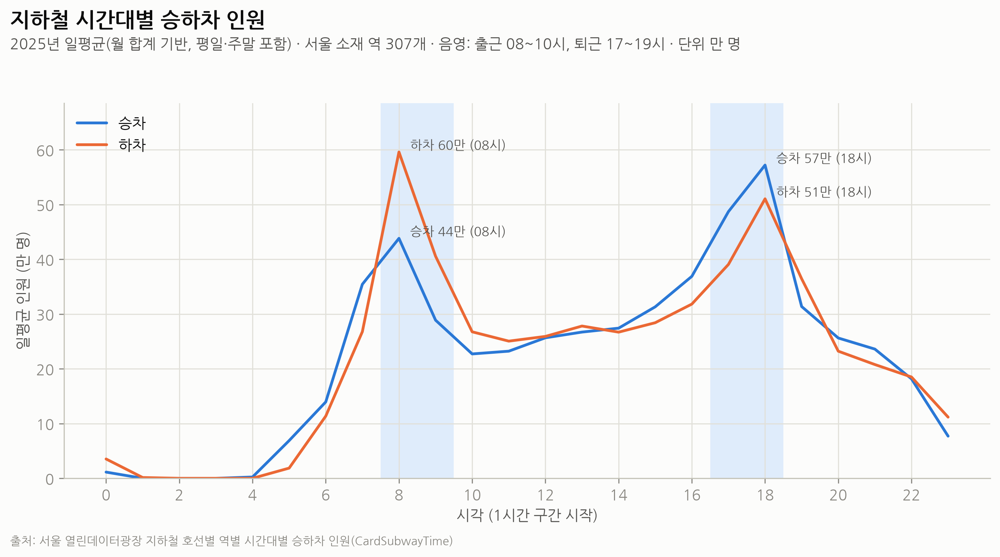

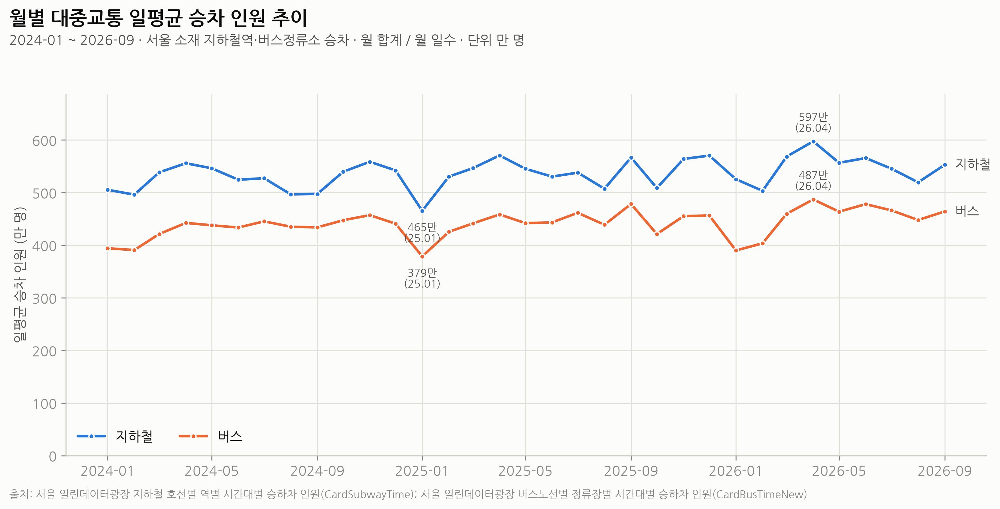

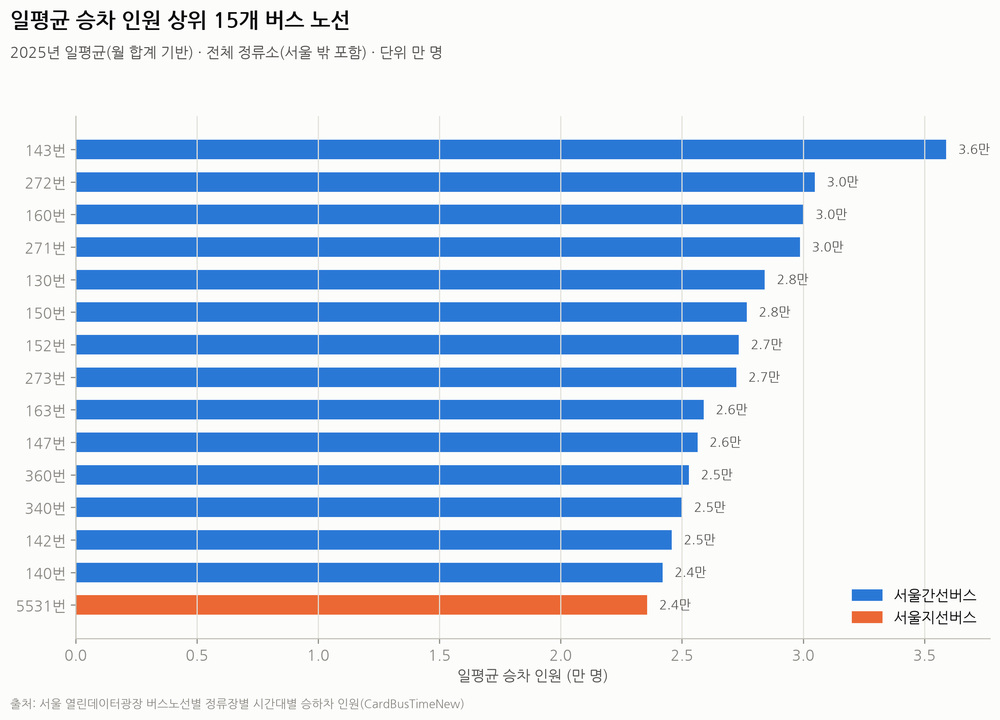

In [8]:
show('C01_지하철_시간대별_승하차'); show('C02_월별_대중교통_이용추이'); show('C03_버스노선_승차상위15', 700)

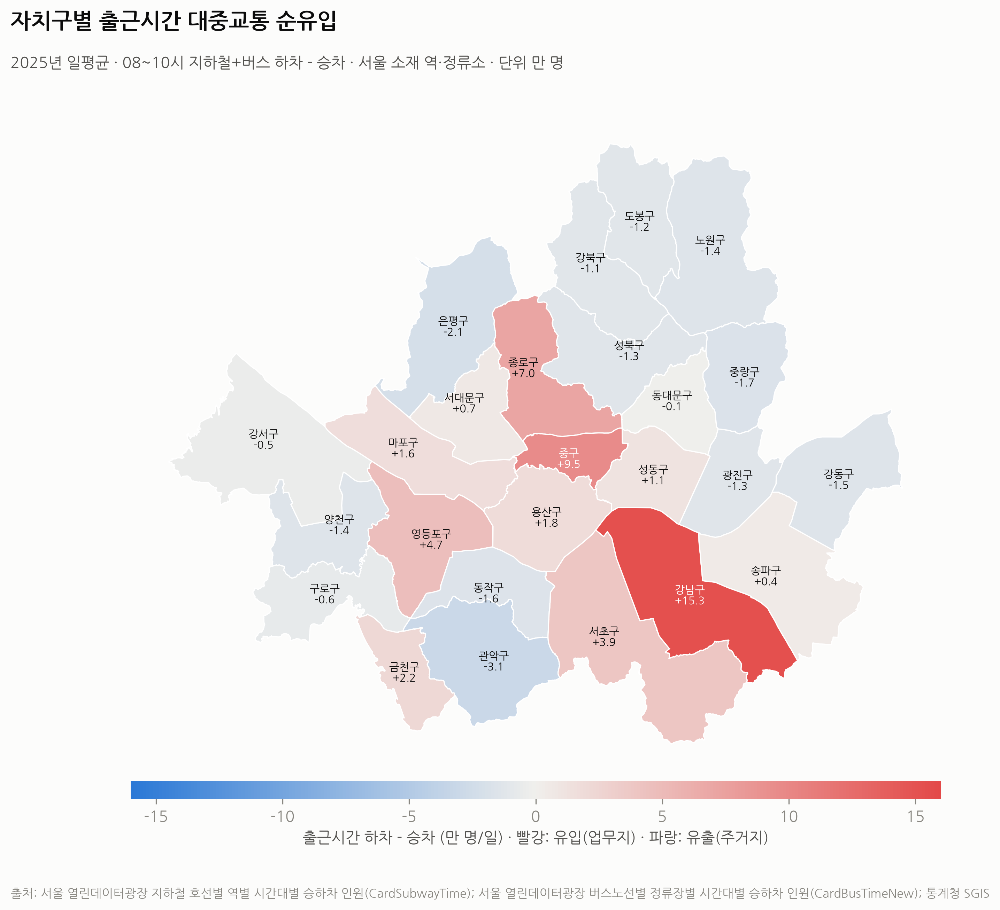

,자치구,승차,하차,순유입,지하철_board,버스_board
4,관악구,83603.0,52562.0,-31041.0,49158.0,34445.0
21,은평구,63710.0,42280.0,-21430.0,37921.0,25789.0
24,중랑구,43952.0,27387.0,-16566.0,23612.0,20341.0
11,동작구,67336.0,51312.0,-16024.0,41754.0,25582.0
1,강동구,42907.0,28207.0,-14700.0,28251.0,14656.0
18,양천구,42540.0,28367.0,-14173.0,22164.0,20376.0
8,노원구,51382.0,37487.0,-13895.0,33217.0,18165.0
5,광진구,48828.0,36031.0,-12798.0,34399.0,14429.0
16,성북구,56352.0,43737.0,-12615.0,25470.0,30882.0
9,도봉구,33649.0,21627.0,-12022.0,17568.0,16081.0


In [9]:
show('C04_자치구별_출근시간_대중교통_순유입', 700); table('C04_자치구별_출근시간_대중교통_순유입').sort_values('순유입')

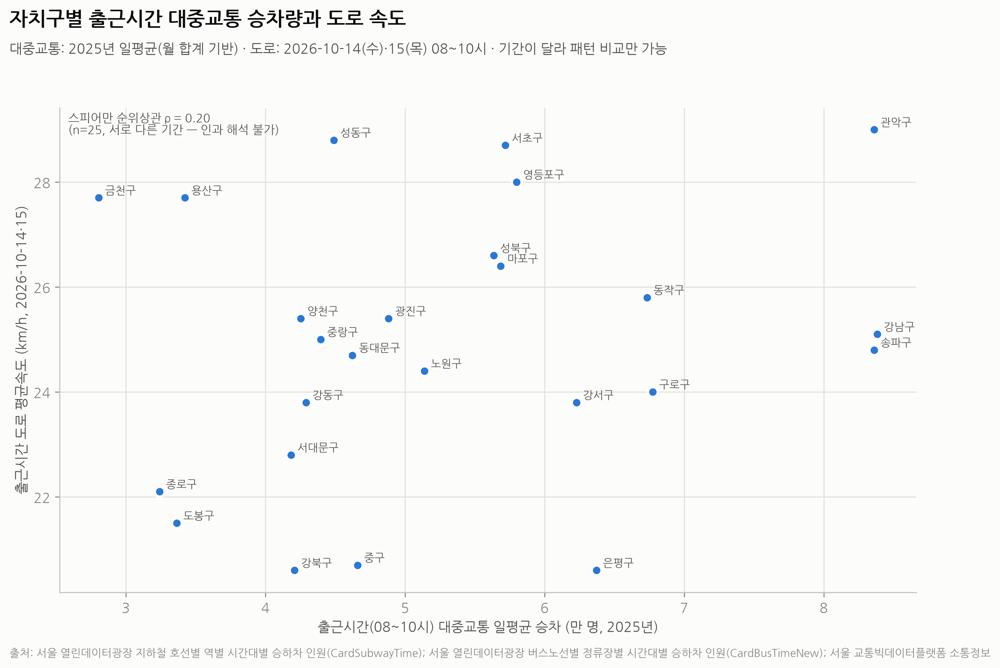

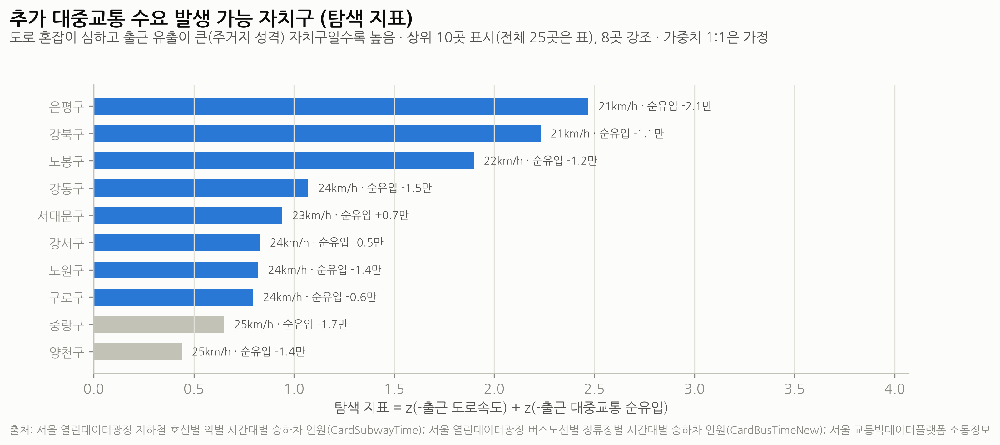

In [10]:
show('C05_자치구별_대중교통승차_vs_도로속도', 700); show('C06_추가대중교통수요_후보자치구')

- 업무지(순유입+): 강남·중구·종로·영등포. 주거지(순유입−): 관악·은평 등.
- 도로가 느리고 출근 유출이 큰 은평·강북·도봉 등 8개 구 = 이동 격차 후보(탐색 지표, 가중치 1:1 가정).
- 데이터 품질: 지하철 API가 2026-03·07을 중복 제공 → 전처리에서 제거(C02가 이를 반영).

## D. 외부 요인 — 교통량·요일·날씨

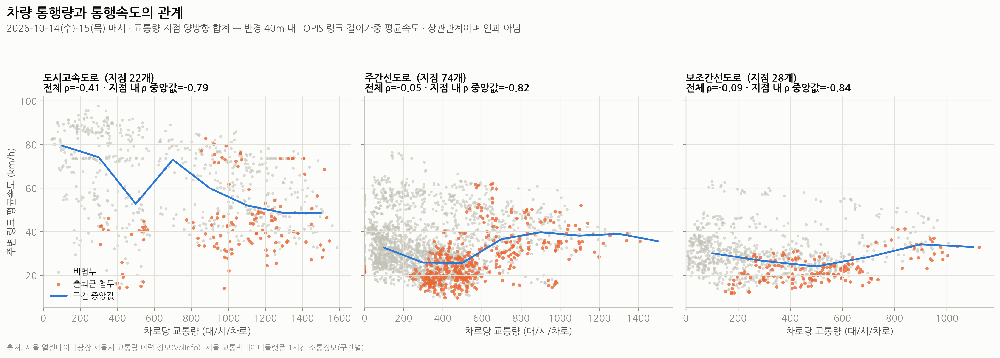

,도로구분,지점수,관측수,spearman_전체,spearman_지점내_중앙값
0,도시고속도로,22,726,-0.415,-0.793
1,주간선도로,74,2424,-0.052,-0.823
2,보조간선도로,28,924,-0.093,-0.838


In [11]:
show('D01_교통량_속도_관계'); table('D01_교통량_속도_관계')

- 지점을 섞으면 간선도로 상관이 약하지만, 같은 지점 안에서는 ρ ≈ −0.8 → 정책 효과는 구간별 관계로 추정(시뮬레이션의 근거).
- 소통정보 33시간 동안 강수가 없어 강수-속도는 분석 불가.

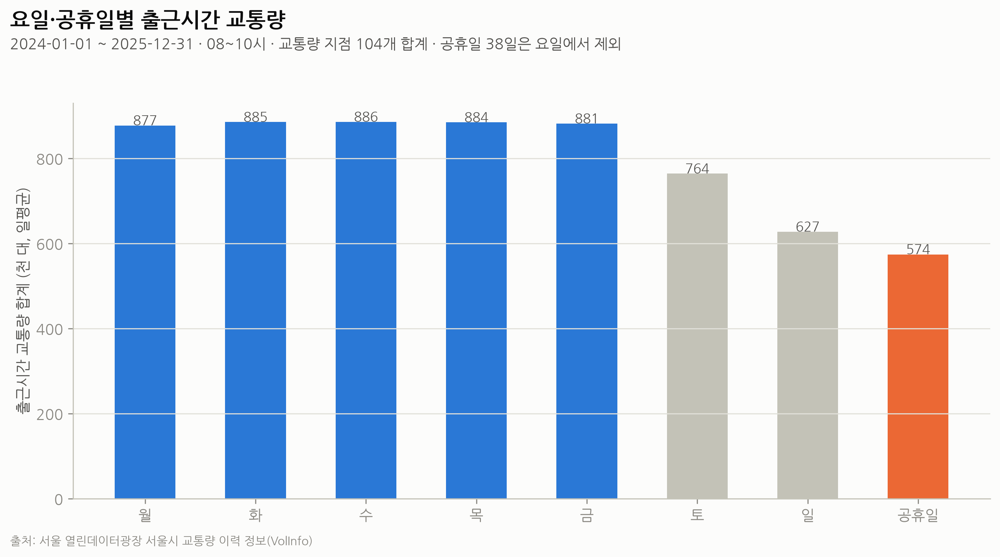

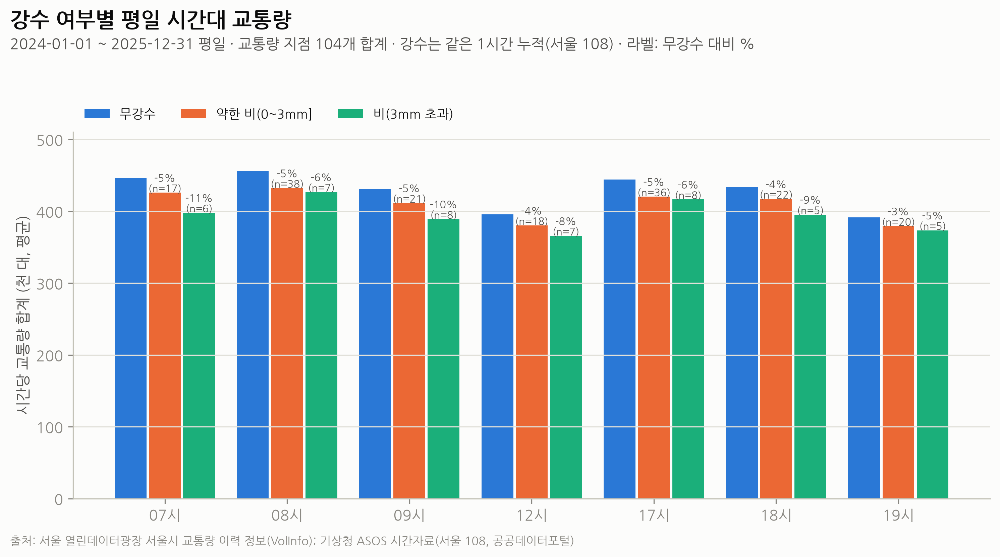

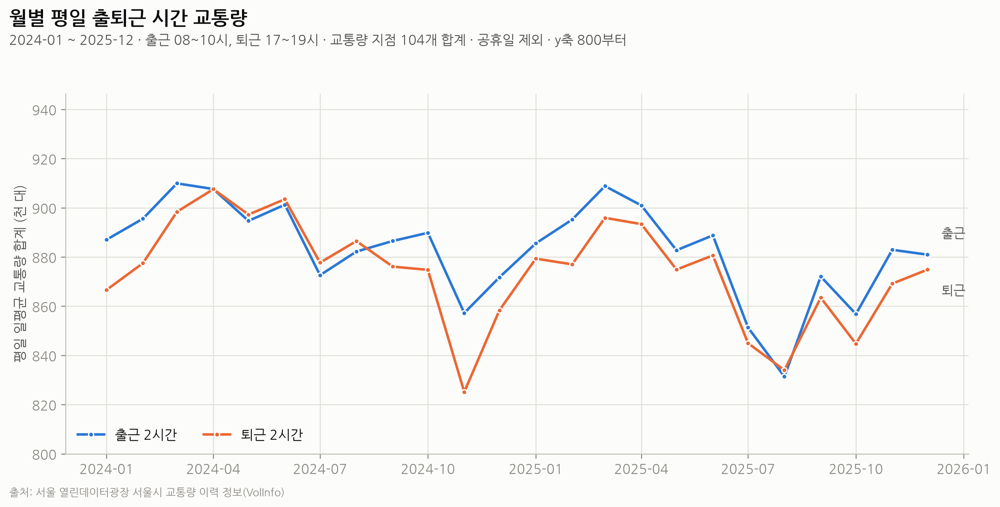

In [12]:
# 장기 교통량(2024~2025) 기반 요일·강수·월별 — eda_factors.py --long 실행 후 생성
for n in ['D02_요일공휴일별_출근교통량', 'D03_강수여부별_교통량', 'D04_월별_출퇴근_교통량']:
    if (FIG/f'{n}.png').exists():
        show(n)
    else:
        print(f'{n}: 아직 없음 (장기 교통량 수집 후 생성)')

- 장기 교통량 725일(6일은 원천 자료 없음), 07~19시 교통량 0(1.9%)은 검지기 장애로 결측 처리, 95% 이상 관측된 104개 지점 합계.
- D02: 평일 요일 간 차이 1% 이내. 토 -13.5%, 일 -28.9%, 공휴일 -35.0% → 요일보다 근무일 여부가 결정.
- D03: 약한 비 -3~-5%, 3mm 초과 -5~-11%(시간대별 5~8시간뿐이라 불확실).
- D04: 월별 83만~91만 대(±5%) → 첨두 혼잡은 연중 구조적.

## E. AI 예측 (참고) — 첨두 교통량 1시간 전 예측

결과 생성: `src/models/forecast_volume.py`. 정책 효과 추정이 아님.

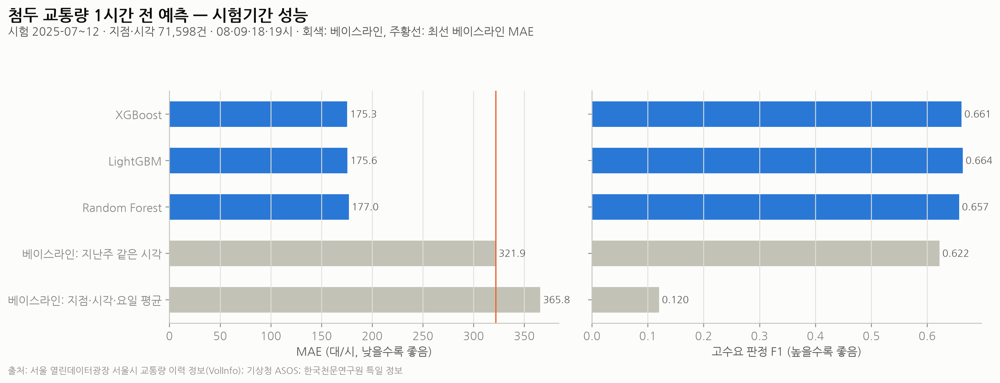

,model,split,MAE,RMSE,MAPE_pct,F1,Precision,Recall
1,베이스라인: 지난주 같은 시각,test,321.9186,623.4608,25.8887,0.6220,0.6146,0.6296
3,베이스라인: 지점·시각·요일 평균,test,365.7559,605.6710,30.9897,0.1201,0.5284,0.0678
5,Random Forest,test,177.0129,283.5122,12.4523,0.6570,0.7694,0.5733
7,XGBoost,test,175.3395,277.8256,14.1347,0.6613,0.7658,0.5819
9,LightGBM,test,175.6436,277.0806,14.0376,0.6637,0.7537,0.5928


In [13]:
show('E01_예측모델_성능비교'); pd.read_csv(TAB / 'model_forecast_metrics.csv').query('split == "test"')

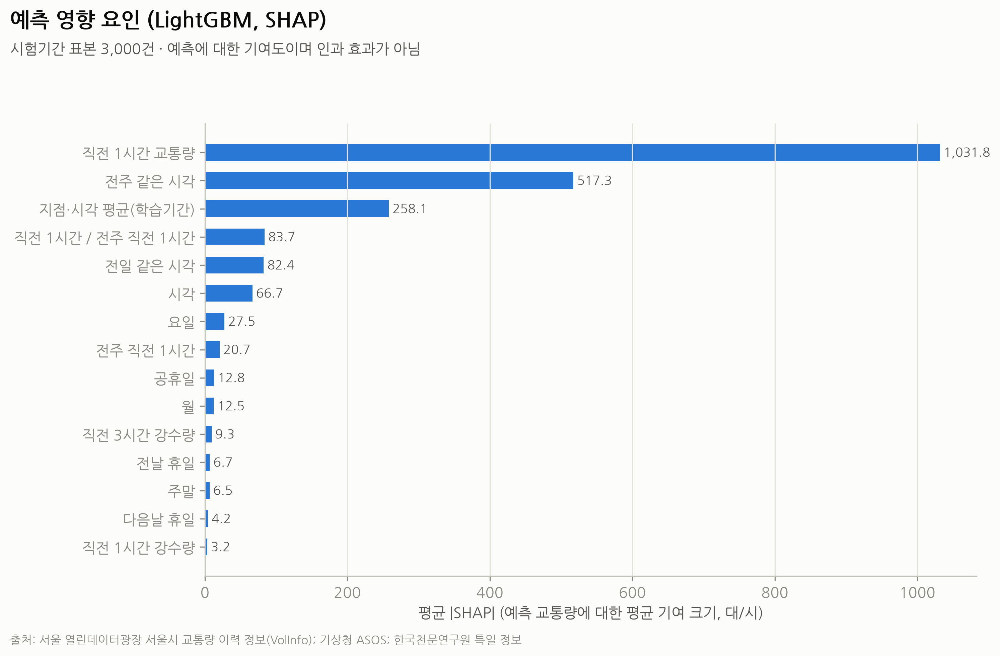

In [14]:
show('E02_예측영향요인_SHAP', 700)

- 시험기간 MAE: 최선 베이스라인 322 → XGBoost 175(-45%). 고수요 F1은 0.62 → 0.66으로 개선이 작음.
- SHAP 상위: 직전 1시간·지난주 같은 시각 교통량. 예측 기여도이며 인과 효과 아님.